# PfCSP figures

Every figure of the report, built from the pipeline output. Run the pipeline first,
then run this notebook top to bottom.

Set `OUT_DIR`, `REPO` and `METADATA` in the first cell. Nothing else needs editing.

Author: Khadim Gueye

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..").resolve()
OUT_DIR = Path("/home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output")
METADATA = Path("/home/gueyekhadim/work/data/malaria_team/Input_Raw_Data/ICEMR_CRID_CSP/metadata.tsv")
FIG_DIR = OUT_DIR / "10_figures"

CALLABLE_START, CALLABLE_END = 221345, 221643
AMPLICON_START = 221320
TH2R, TH3R = (311, 327), (352, 367)
COUNTRY_A, COUNTRY_B = "Nigeria", "Cameroon"

sys.path.insert(0, str(REPO / "notebook"))
import csp_lib as L
import csp_figure9

FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "font.size": 10})
print("output:", OUT_DIR)

output: /home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output


## Load

In [2]:
meta = L.load_metadata(METADATA)
clones = L.load_clones(OUT_DIR, meta)
moi = L.load_moi(OUT_DIR, meta)

# The 3D7 window, same coordinates and strand as the clone sequences.
amplicon = list(L.read_fasta(REPO / "reference" / "pfcsp_amplicon.fasta").values())[0]
offset = CALLABLE_START - AMPLICON_START
REF_NT = amplicon[offset:offset + (CALLABLE_END - CALLABLE_START + 1)]
assert len(REF_NT) == len(clones.nt.iloc[0])

# A clone whose bases are not all resolved is dropped. Keeping it would blank the
# informative columns for every other sequence in the pool.
dropped = clones.loc[~clones.usable, "clone"].tolist()
clones = clones[clones.usable].reset_index(drop=True)

n_controls = L.count_controls(OUT_DIR)
print(f"{len(meta)} samples, {len(clones)} clones, {n_controls} controls")
if dropped:
    print(f"dropped for unresolved bases: {len(dropped)} ({', '.join(dropped)})")
print(clones.groupby("country").size().to_string())

184 samples, 374 clones, 8 controls
dropped for unresolved bases: 1 (CMR-C-8606_H1)
country
Cameroon    279
Nigeria      95


## Figure 1. Samples per country

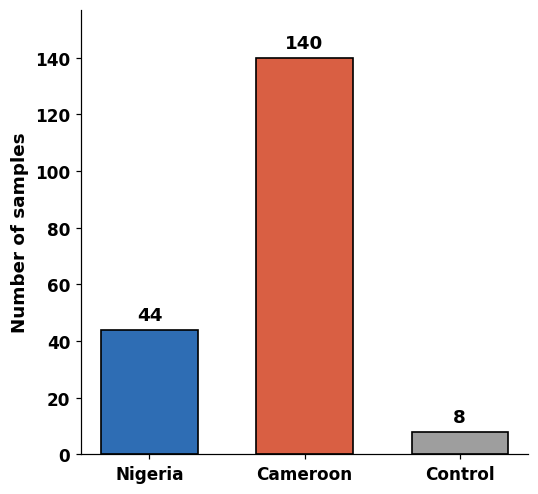

In [3]:
fig1 = L.fig_sample_counts(meta, n_controls)
fig1.savefig(FIG_DIR / "fig1_sample_counts.png", dpi=300)
plt.show()

## Figure 2. Multiplicity of infection by state

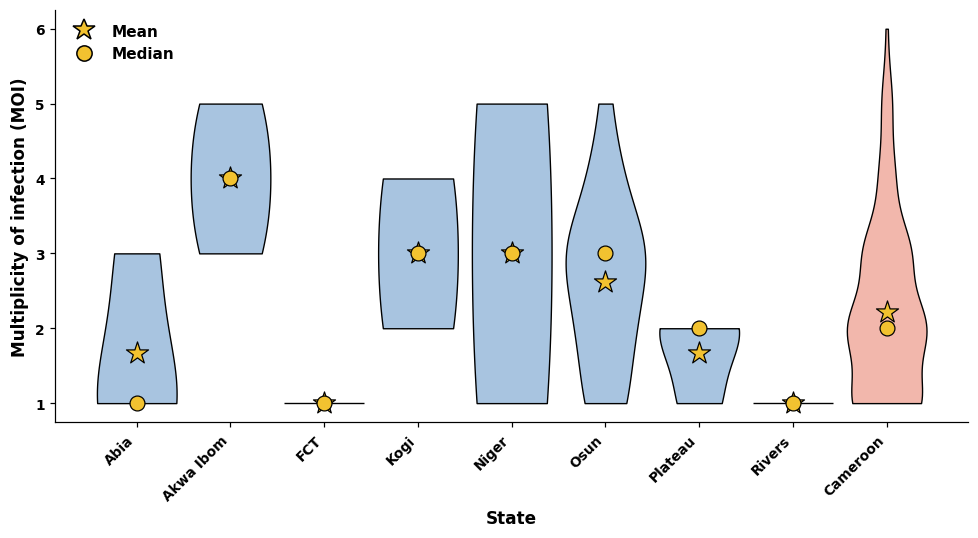

            n  mean  median  low  high
state                                 
Abia        3  1.67     1.0    1     3
Akwa Ibom   3  4.00     4.0    3     5
FCT         3  1.00     1.0    1     1
Kogi        2  3.00     3.0    2     4
Niger       2  3.00     3.0    1     5
Osun       21  2.62     3.0    1     5
Plateau     3  1.67     2.0    1     2
Rivers      3  1.00     1.0    1     1

polyclonal: Cameroon 87/126 (69%), Nigeria 26/40 (65%)


In [4]:
fig2 = L.fig_moi(moi, COUNTRY_A, COUNTRY_B)
fig2.savefig(FIG_DIR / "fig2_moi_by_state.png", dpi=300)
plt.show()

summary = (moi[moi.country == COUNTRY_A].groupby("state")["MOI"]
           .agg(n="size", mean="mean", median="median", low="min", high="max").round(2))
print(summary.to_string())
print(f"\npolyclonal: " + ", ".join(
    f"{c} {int((g.MOI > 1).sum())}/{len(g)} ({100 * (g.MOI > 1).mean():.0f}%)"
    for c, g in moi.groupby("country")))

## Figure 3. Nucleotide and haplotype diversity

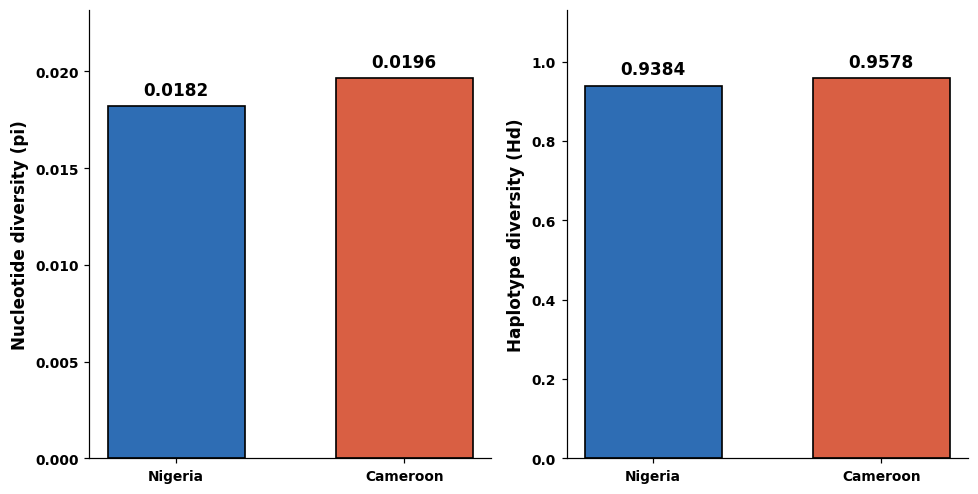

Cameroon   pi 0.0196   Hd 0.9578   clones 279   haplotypes 72
Nigeria    pi 0.0182   Hd 0.9384   clones 95   haplotypes 36


In [5]:
fig3 = L.fig_diversity(clones, COUNTRY_A, COUNTRY_B)
fig3.savefig(FIG_DIR / "fig3_diversity.png", dpi=300)
plt.show()

for c, g in clones.groupby("country"):
    print(f"{c:<10} pi {L.nucleotide_diversity(g.nt.tolist()):.4f}   "
          f"Hd {L.haplotype_diversity(g.nt.tolist()):.4f}   "
          f"clones {len(g)}   haplotypes {g.nt.nunique()}")

## Figure 4. Where the variation sits

Panel A is read from the per sample calls, so it reflects within host mixture.
Panels B and C are read from the consensus substitutions, one row per change.

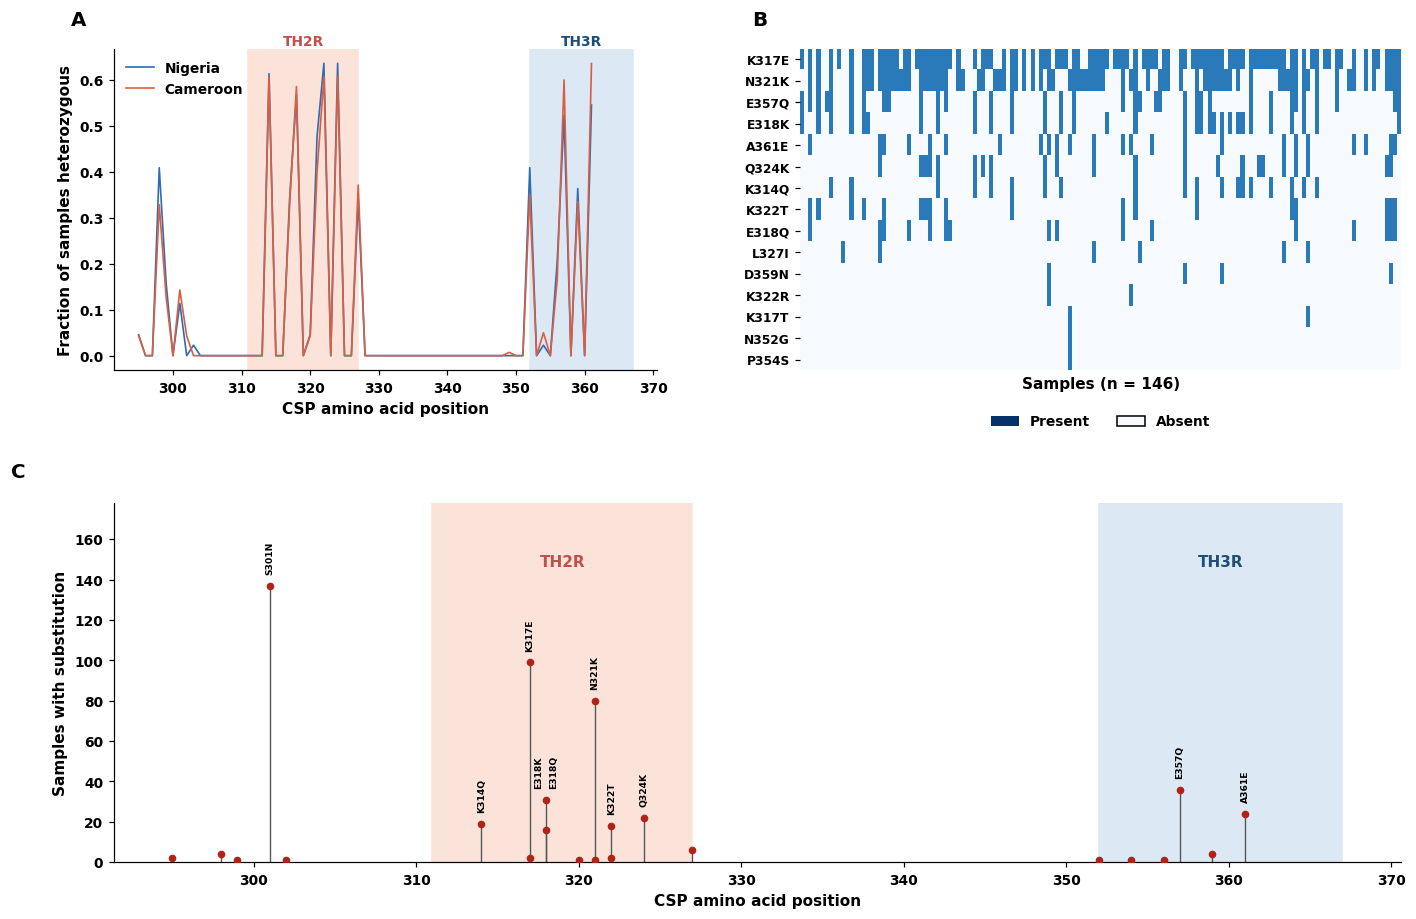

samples with at least one heterozygous codon: {'Cameroon': 109, 'Nigeria': 32}


In [6]:
het = L.heterozygous_codons(OUT_DIR, meta, REPO / "reference" / "pfcsp_codon_map.tsv",
                            CALLABLE_START, CALLABLE_END)

subs = pd.read_csv(OUT_DIR / "08_protein" / "substitutions_consensus.tsv", sep="\t")
subs = subs[subs["sample"].isin(meta.index)].copy()
subs["country"] = subs["sample"].map(meta["country"])

n_by_country = meta["country"].value_counts().to_dict()
window = (int(subs.aa_position.min()), int(subs.aa_position.max()))

fig4 = L.fig_substitutions(het, subs, TH2R, TH3R, n_by_country, window)
fig4.savefig(FIG_DIR / "fig4_substitutions.png", dpi=300)
plt.show()

print("samples with at least one heterozygous codon:",
      het.groupby("country")["sample"].nunique().to_dict())

## Figure 7. Vaccine match status

The consensus level leaves many samples unscorable, because a heterozygous position
collapses into one ambiguous code. Scoring each phased clone removes that.

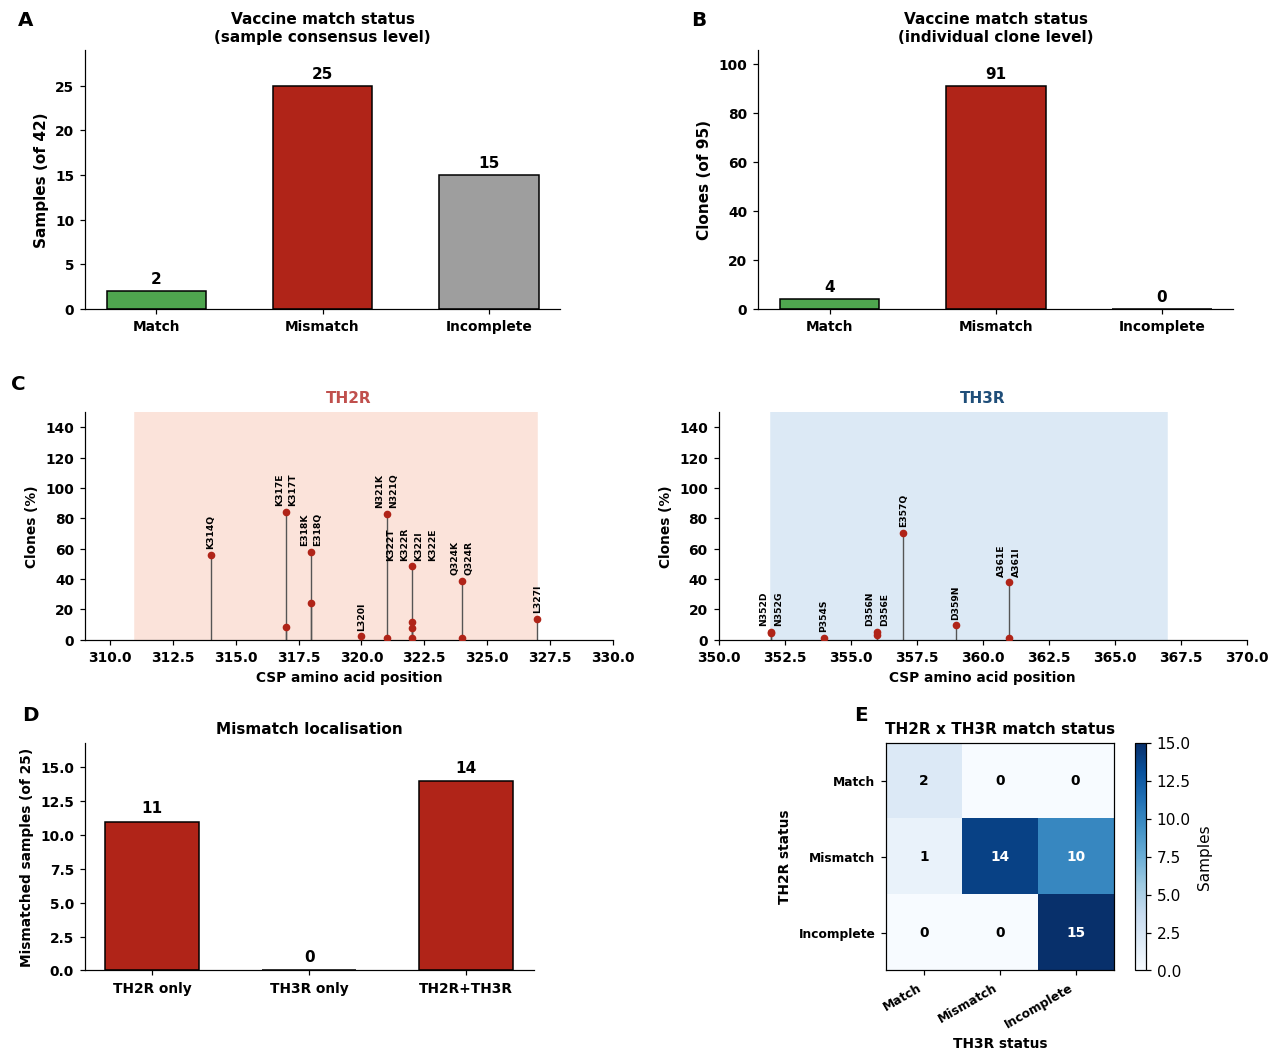

consensus: {'mismatch': 25, 'incomplete': 15, 'match': 2}
clones   : {'mismatch': 91, 'match': 4}
localisation: {'TH2R+TH3R': 14, 'TH2R only': 11}


In [7]:
cons = pd.read_csv(OUT_DIR / "08_protein" / "epitope_status_consensus.tsv", sep="\t")
cons = cons[cons["sample"].isin(meta.index)].copy()
cons["country"] = cons["sample"].map(meta["country"])
cons = cons[cons.country == COUNTRY_A].fillna("")

eps = pd.read_csv(OUT_DIR / "08_protein" / "epitope_status_haplotypes.tsv", sep="\t")
eps["country"] = eps["sample"].map(meta["country"])
eps = eps[eps.country == COUNTRY_A]

sub_h = pd.read_csv(OUT_DIR / "08_protein" / "substitutions_haplotypes.tsv", sep="\t")
sub_h["country"] = sub_h["sample"].map(meta["country"])
sub_h = sub_h[sub_h.country == COUNTRY_A]

fig7 = L.fig_vaccine_match(cons, eps, TH2R, TH3R, sub_h)
fig7.savefig(FIG_DIR / "fig7_vaccine_match.png", dpi=300)
plt.show()

print("consensus:", cons.vaccine_status.value_counts().to_dict())
print("clones   :", eps.vaccine_status.value_counts().to_dict())
print("localisation:", cons.loc[cons.vaccine_status == "mismatch",
                                "mismatch_localisation"].value_counts().to_dict())

## Figure 8. Population structure, with 3D7 on the PCoA

The 3D7 reference is one more point on the ordination, so the distance between the
field sequences and the vaccine sequence can be read directly.

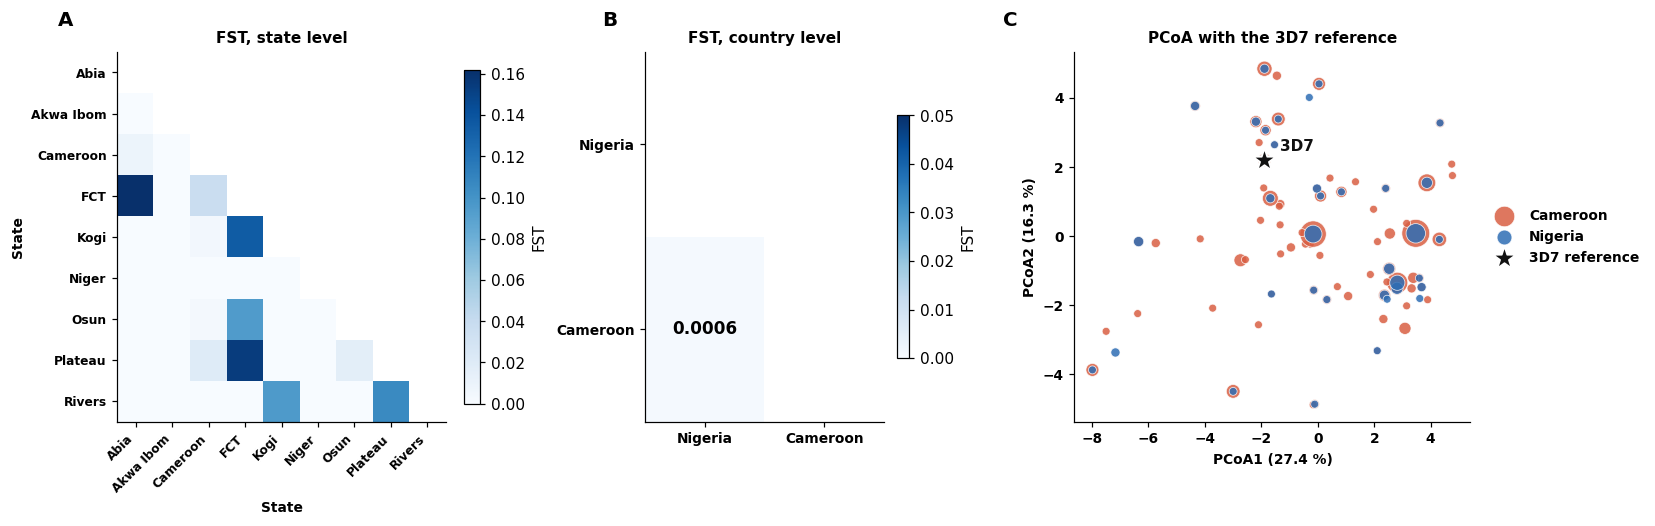

PCoA1 27.4 %, PCoA2 16.3 %


country FST: 0.0006
            n  mean  low  high
country                       
Cameroon  279  7.33    0    10
Nigeria    95  7.06    0    10


In [8]:
fig8, coords, explained = L.fig_structure(clones, REF_NT, COUNTRY_A, COUNTRY_B)
fig8.savefig(FIG_DIR / "fig8_structure.png", dpi=300)
plt.show()

print(f"PCoA1 {explained[0]:.1f} %, PCoA2 {explained[1]:.1f} %")
if (clones.country == COUNTRY_B).any():
    print("country FST:", round(L.hudson_fst(
        clones.loc[clones.country == COUNTRY_A, "nt"].tolist(),
        clones.loc[clones.country == COUNTRY_B, "nt"].tolist()), 4))

dist = L.distance_to_reference(clones, REF_NT)
dist.to_csv(FIG_DIR / "clone_distance_to_3d7.tsv", sep="\t", index=False)
print(dist.groupby("country")["nt_differences_vs_3d7"]
      .agg(n="size", mean="mean", low="min", high="max").round(2).to_string())

## Figure 9. Protein haplotypes against 3D7

Drawn by `csp_figure9.py`, the same code the pipeline used, so the plot is unchanged.
Edit the argument list to change the cohort or the printed size.

[INFO] window: amino acids 292 to 390, 99 residues
[INFO] 36 nucleotide haplotypes translate into 36 protein haplotypes, 0 of them merging more than one
[INFO] no nucleotide haplotype pair differs by silent changes only, so translation merges nothing
[INFO] cohort: samples not starting with CMR
[INFO] 95 clones, 36 protein haplotypes, 20 variable positions
[INFO] 8 state(s): Abia, Akwa Ibom, FCT, Kogi, Niger, Osun, Plateau, Rivers
[INFO] drawing 36 of 36 haplotypes
[OK] /home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/10_figures/protein_haplotypes.tsv (36 haplotypes)
[OK] /home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/10_figures/protein_variable_positions.tsv (20 positions)
[INFO] clones identical to 3D7 over the window: 4, over Th2R: 4, over Th3R: 7


[INFO] figure 7.50 x 9.30 in, row 0.161 in, residue 8.2 pt
[OK] /home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/10_figures/csp_protein_vs_3d7.pdf
[OK] /home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/10_figures/csp_protein_vs_3d7.png


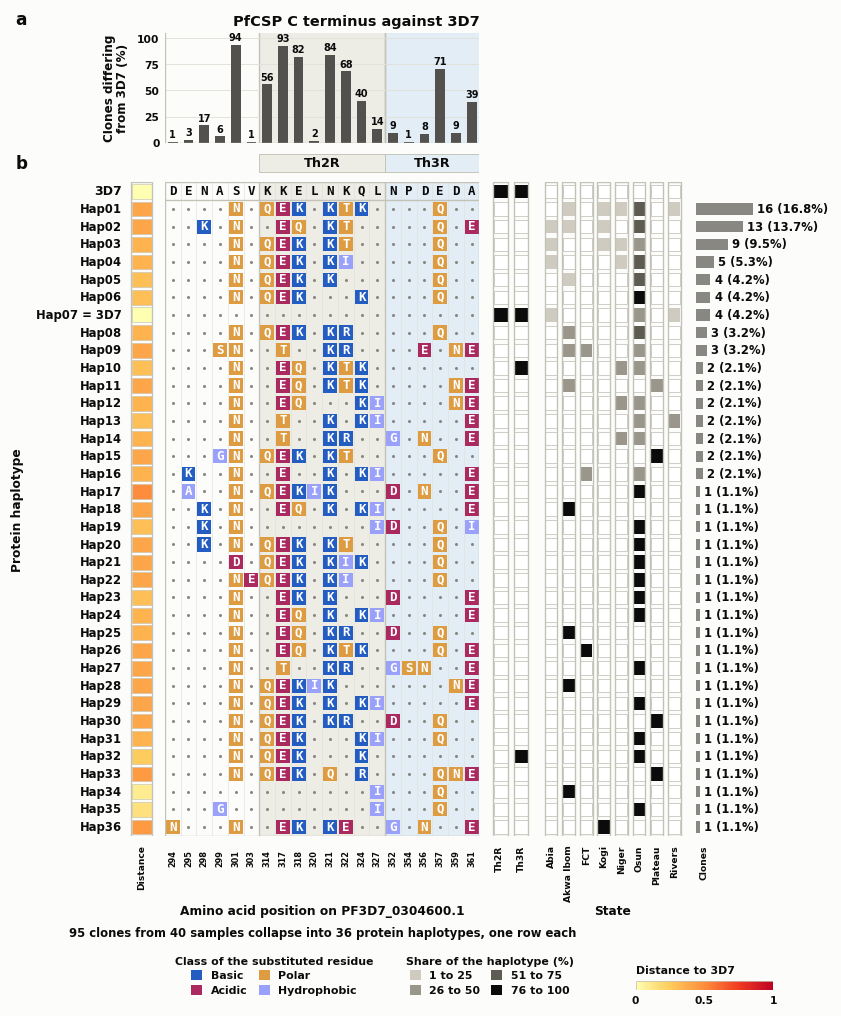

In [9]:
fig9 = csp_figure9.main([
    "--out-dir", str(OUT_DIR),
    "--codon-map", str(REPO / "reference" / "pfcsp_codon_map.tsv"),
    "--callable-start", str(CALLABLE_START),
    "--callable-end", str(CALLABLE_END),
    "--th2r", str(TH2R[0]), str(TH2R[1]),
    "--th3r", str(TH3R[0]), str(TH3R[1]),
    "--metadata", str(METADATA),
    "--exclude-prefix", "CMR",
    "--cameroon-prefix", "CMR",
    "--page-width", "7.5",
    "--page-height", "9.3",
    "--title", "PfCSP C terminus against 3D7",
    "--dpi", "600",
])
plt.show()

## Figure 10. Phylogeny

The tree is drawn in iTOL, not here. Load the newick, then drop the annotations on it
in the order printed below, each ring label immediately before the ring it names.

In [10]:
tree_dir = OUT_DIR / "09_phylogeny" / "nigeria"
for name in ("nigeria.rooted.nwk", "itol_labelcolors_origin.txt",
             "itol_ringlabel_origin.txt", "itol_colorstrip_origin.txt",
             "itol_ringlabel_our_clones.txt", "itol_symbol_our_clones.txt",
             "itol_ringlabel_region.txt", "itol_piechart_by_region.txt",
             "itol_ringlabel_country.txt", "itol_piechart_by_country.txt"):
    print(tree_dir / name)

haps = pd.read_csv(tree_dir / "metadata_haplotypes.tsv", sep="\t")
ours = haps[haps.n_our_clones > 0]
alone = ours[ours.n_pf8_samples == 0]
shared = ours[ours.n_pf8_samples > 0]
print(f"\n{len(haps)} tips, {len(ours)} carry our {int(ours.n_our_clones.sum())} clones")
print(f"ours alone {len(alone)} ({int(alone.n_our_clones.sum())} clones), "
      f"shared with Pf8 {len(shared)} ({int(shared.n_our_clones.sum())} clones)")
print(pd.read_csv(tree_dir / "nigeria.support_summary.tsv", sep="\t").to_string(index=False))

/home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/09_phylogeny/nigeria/nigeria.rooted.nwk
/home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/09_phylogeny/nigeria/itol_labelcolors_origin.txt
/home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/09_phylogeny/nigeria/itol_ringlabel_origin.txt
/home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/09_phylogeny/nigeria/itol_colorstrip_origin.txt
/home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/09_phylogeny/nigeria/itol_ringlabel_our_clones.txt
/home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/09_phylogeny/nigeria/itol_symbol_our_clones.txt
/home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/09_phylogeny/nigeria/itol_ringlabel_region.txt
/home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_outpu